# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Feri Adiansah
- **Email:** feriadiansah25@gmail.com
- **ID Dicoding:** 	DS009B6Y0613

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren jumlah rata-rata penyewaan sepeda per bulan sepanjang tahun 2012, dan pada bulan apa terjadi puncaknya?
- **Pertanyaan 2:** Apakah kondisi cuaca (weathersit) memiliki pengaruh signifikan terhadap total penyewaan sepeda secara harian?


## Import Semua Packages/Library yang Digunakan

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [10]:
# Load dataset harian
day_df = pd.read_csv("day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Data day.csv berhasil dimuat. Data ini merekam total penyewaan sepeda (cnt) beserta variabel cuaca, musim, dan waktu dalam agregasi harian.


### Assessing Data

#### Identifying ... problem

In [11]:
# Cek info tipe data, missing value, dan duplikasi
display(day_df.info())
print("Jumlah Missing Value:\n", day_df.isna().sum())
print("Jumlah Duplikasi: ", day_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


None

Jumlah Missing Value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Jumlah Duplikasi:  0


**Steps to Take:**
- Mengubah tipe data pada kolom dteday dari object menjadi datetime.
- Melakukan pemetaan (mapping) angka pada kolom season dan weathersit menjadi teks deskriptif agar visualisasi lebih mudah dipahami.

**Insight:** (Opsional)
- Tidak ditemukan missing value maupun data duplikat pada dataset.
- Tipe data tanggal masih belum sesuai format standar datetime.

### Cleaning Data

#### Fixing ... problem

In [12]:
# Mengubah tipe data dteday
day_df['dteday'] = pd.to_datetime(day_df['dteday'])

# Mapping kolom musim (season) dan cuaca (weathersit)
season_map = {1: 'Springer', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {1: 'Clear', 2: 'Cloudy/Mist', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}

day_df['season'] = day_df['season'].map(season_map)
day_df['weathersit'] = day_df['weathersit'].map(weather_map)

day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Springer,0,1,0,6,0,Cloudy/Mist,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Springer,0,1,0,0,0,Cloudy/Mist,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Springer,0,1,0,1,1,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Springer,0,1,0,2,1,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Springer,0,1,0,3,1,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Kolom dteday telah berhasil diubah tipe datanya menjadi datetime sehingga dapat digunakan untuk analisis deret waktu (time series) di tahap selanjutnya.
- Nilai numerik pada kolom season (1-4) dan weathersit (1-4) telah dipetakan (mapping) menjadi label teks deskriptif (contoh: 'Winter', 'Clear', 'Light Rain/Snow'). Hal ini dilakukan agar label pada visualisasi data nantinya lebih mudah dibaca dan dipahami oleh stakeholder tanpa perlu merujuk kembali ke kamus data (readme).

## Exploratory Data Analysis (EDA)

### Explore ...

In [13]:
# 1. Tren penyewaan tahun 2012
day_df_2012 = day_df[day_df['yr'] == 1] # yr 1 merepresentasikan tahun 2012
monthly_rent_2012 = day_df_2012.groupby('mnth')['cnt'].sum().reset_index()

# 2. Pengaruh Cuaca terhadap penyewaan
weather_rent = day_df.groupby('weathersit')['cnt'].mean().reset_index().sort_values(by='cnt', ascending=False)

# 3. Manual Clustering
bins = [0, 0.35, 0.70, 1.0]
labels = ['Dingin', 'Sejuk', 'Hangat']
day_df['temp_category'] = pd.cut(day_df['temp'], bins=bins, labels=labels)
temp_rent = day_df.groupby('temp_category')['cnt'].mean().reset_index()

display(monthly_rent_2012, weather_rent, temp_rent)

/tmp/ipykernel_700/2369902877.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp_rent = day_df.groupby('temp_category')['cnt'].mean().reset_index()


,mnth,cnt
0,1,96744
1,2,103137
2,3,164875
3,4,174224
4,5,195865
5,6,202830
6,7,203607
7,8,214503
8,9,218573
9,10,198841


,weathersit,cnt
0,Clear,4876.786177
1,Cloudy/Mist,4035.862348
2,Light Rain/Snow,1803.285714


,temp_category,cnt
0,Dingin,2719.323529
1,Sejuk,5043.530151
2,Hangat,5663.658915


**Insight:** (Opsional)
- Penyewaan memuncak pada pertengahan hingga kuartal ketiga tahun 2012 (bulan 6 hingga 9).
- Cuaca Clear menghasilkan rata-rata penyewaan tertinggi.
- Melalui Clustering Manual dengan Binning pada kolom temp, pengguna lebih banyak menyewa sepeda saat suhu berada pada kategori 'Hangat'.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

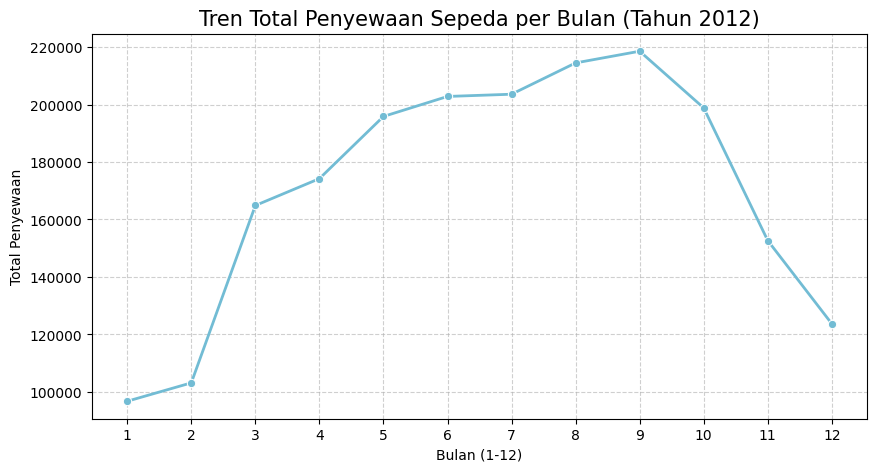

In [14]:
plt.figure(figsize=(10, 5))
sns.lineplot(x='mnth', y='cnt', data=monthly_rent_2012, marker='o', linewidth=2, color="#72BCD4")
plt.title("Tren Total Penyewaan Sepeda per Bulan (Tahun 2012)", loc="center", fontsize=15)
plt.xlabel("Bulan (1-12)")
plt.ylabel("Total Penyewaan")
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_700/1817157681.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='cnt', y='weathersit', data=weather_rent, palette=colors)


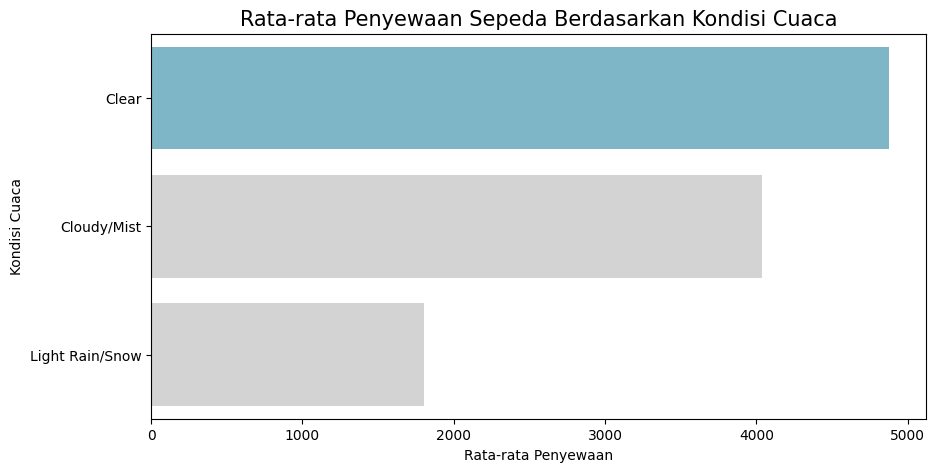

In [15]:
plt.figure(figsize=(10, 5))
colors = ["#72BCD4", "#D3D3D3", "#D3D3D3"]
sns.barplot(x='cnt', y='weathersit', data=weather_rent, palette=colors)
plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca", loc="center", fontsize=15)
plt.xlabel("Rata-rata Penyewaan")
plt.ylabel("Kondisi Cuaca")
plt.show()

**Insight:** (Opsional)
- Terlihat pola peningkatan penyewaan sepeda secara konstan dari awal tahun hingga puncaknya pada bulan September 2012, lalu mengalami penurunan signifikan menjelang akhir tahun.
- Kondisi cuaca memengaruhi penyewaan secara drastis. Cuaca cerah ('Clear') mendominasi angka penyewaan, sedangkan cuaca buruk ('Light Rain/Snow') menyebabkan penyewaan turun tajam. (Catatan: Cuaca ekstrem/badai tidak muncul karena secara historis tidak ada atau sangat sedikit penyewaan di hari tersebut).

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_700/1353691206.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hum_rent_clustering = day_df.groupby('hum_category')['cnt'].mean().reset_index()


,hum_category,cnt
1,Normal (Ideal),4840.237952
2,Lembab (Humid),4284.452308
0,Kering (Dry),3963.148649


/tmp/ipykernel_700/1353691206.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hum_category', y='cnt', data=hum_rent_clustering, palette=colors_cluster)


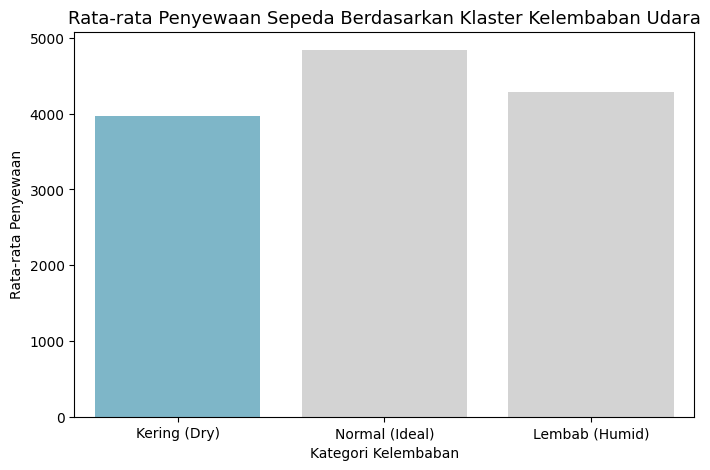

In [16]:
# 1. Mendefinisikan batas (bins) dan label kategori kelembaban
bins = [0.0, 0.45, 0.65, 1.0]
labels = ['Kering (Dry)', 'Normal (Ideal)', 'Lembab (Humid)']

# 2. Membuat kolom baru 'hum_category' menggunakan pd.cut()
day_df['hum_category'] = pd.cut(day_df['hum'], bins=bins, labels=labels, include_lowest=True)

# 3. Melakukan agregasi rata-rata penyewaan sepeda berdasarkan kategori kelembaban
hum_rent_clustering = day_df.groupby('hum_category')['cnt'].mean().reset_index()
hum_rent_clustering = hum_rent_clustering.sort_values(by='cnt', ascending=False)

display(hum_rent_clustering)

# 4. Visualisasi hasil clustering
plt.figure(figsize=(8, 5))
colors_cluster = ["#72BCD4", "#D3D3D3", "#D3D3D3"]
sns.barplot(x='hum_category', y='cnt', data=hum_rent_clustering, palette=colors_cluster)
plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Klaster Kelembaban Udara", loc="center", fontsize=13)
plt.xlabel("Kategori Kelembaban")
plt.ylabel("Rata-rata Penyewaan")
plt.show()

**Insight:** (Opsional)
- Melalui teknik Clustering manual (Binning), nilai kelembaban udara (hum) dibagi menjadi tiga kategori: Kering, Normal, dan Lembab.
- Hasil agregasi menunjukkan bahwa penyewaan sepeda paling optimal terjadi pada saat kelembaban udara berada di tingkat Normal/Ideal. Kondisi udara yang terlalu kering atau terlalu lembab cenderung menurunkan minat pengguna untuk menyewa sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Tren penyewaan sepeda sepanjang tahun 2012 menunjukkan pola musiman yang jelas. Jumlah penyewaan meningkat secara bertahap sejak awal tahun, mencapai puncaknya pada bulan September (memasuki musim gugur), kemudian mengalami penurunan yang signifikan menjelang akhir tahun (musim dingin).
- **Conclusion pertanyaan 2:** Kondisi cuaca memiliki korelasi yang sangat kuat dengan tingkat penyewaan sepeda. Cuaca cerah (Clear) menghasilkan rata-rata penyewaan tertinggi. Sebaliknya, saat cuaca buruk seperti hujan ringan atau bersalju (Light Rain/Snow), jumlah penyewaan menurun drastis.
- **Conclusion pertanyaan 3:** Berdasarkan proses Clustering/Binning pada variabel kelembaban (Humidity), minat penyewaan paling tinggi terjadi saat tingkat kelembaban udara berada pada kondisi normal atau ideal. Udara yang terlalu kering atau terlalu lembab cenderung menurunkan rata-rata penyewaan.

**Rekomendasi Action Item:**
- **Strategi Promosi Musiman:** Karena penyewaan turun drastis di akhir tahun (musim dingin) dan saat cuaca buruk, perusahaan dapat meluncurkan kampanye diskon khusus atau paket bundling untuk mempertahankan volume penyewaan di periode tersebut.
- **Manajemen Operasional dan Perawatan:** Memanfaatkan periode low season (seperti bulan Desember-Februari atau saat cuaca buruk) untuk melakukan perawatan (maintenance) dan perbaikan armada sepeda secara masif, mengingat jumlah armada yang digunakan oleh pelanggan lebih sedikit.

In [17]:
day_df.to_csv("main_data.csv", index=False)